In [1]:
import os

In [5]:
cwd = os.getcwd()
print(cwd)

/Users/wellscrandall/Documents


In [6]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [8]:
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [9]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [10]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [11]:
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [12]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

model_year
[2006 2008 1996 1989 1994]
50

origin
['Europe' 'Asia' 'USA']
3

fuel_type
['Gasoline' 'Diesel' 'Hybrid']
3

drivetrain
['Front-wheel drive' 'Rear-wheel drive' 'All-wheel drive']
3

num_doors
[4 5 3 2]
4

engine_displacement
[2180 2390 2320 2130 2580]
127

num_cylinders
[6 7 5 8 4]
5

horsepower
[243. 272. 267. 258. 304.]
153

vehicle_weight
[3870 4210 4240 4490 4510]
176

acceleration
[ nan 17.3 18.7 17.5 18.8]
93

fuel_efficiency_mpg
[31.9 31.3 27.5 28.5 31. ]
188



In [21]:
df_set = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

In [22]:
df_set

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

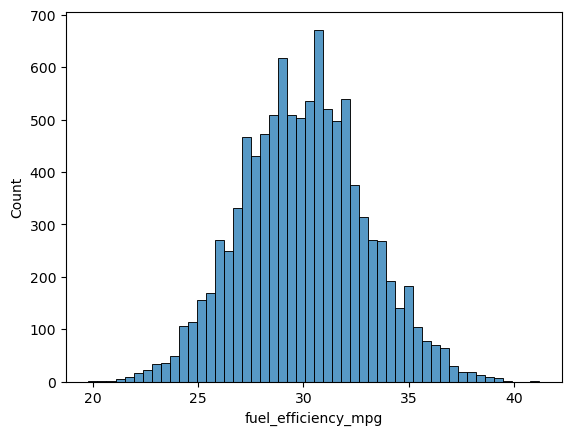

In [23]:
sns.histplot(df_set.fuel_efficiency_mpg, bins = 50)
plt.show()

In [24]:
df_set.isnull()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
9995,False,False,False,False,False
9996,False,False,False,False,False
9997,False,False,False,False,False
9998,False,False,False,False,False


In [25]:
#Question 1

df_set.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [26]:
#Question 2

median_hp = df_set['horsepower'].median()
print(median_hp) 

254.0


In [28]:
n = len(df_set)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_set.iloc[idx[:n_train]]
df_val = df_set.iloc[idx[n_train:n_train + n_val]]
df_test = df_set.iloc[idx[n_train + n_val:]]

In [29]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [30]:
df_set['horsepower'].mean()

254.44601556505535

In [31]:
df_set.mean()

engine_displacement    2268.807000
horsepower              254.446016
vehicle_weight         4286.754000
model_year             1999.549500
fuel_efficiency_mpg      29.997700
dtype: float64

In [173]:
X_train_zero = df_train.fillna(0).values

In [174]:
X_train_zero

array([[2320.,  246., 4100., 2014.],
       [2230.,  252., 4250., 1998.],
       [2700.,  276., 4490., 2008.],
       ...,
       [2180.,  223., 4360., 2014.],
       [2420.,  248., 4080., 1977.],
       [2040.,  245., 4420., 2018.]])

In [175]:
X_train_mean = df_train.fillna(df_set['horsepower'].mean()).values

In [233]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [237]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [238]:
w0_zero, w_zero = train_linear_regression(X_train_zero, y_train)

In [239]:
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [186]:
print(w0_zero, w_zero)

-2.559858322411581 [-4.25865276e-05 -1.09093945e-05 -1.34245303e-04  3.33222963e-03]


In [187]:
print(w0_mean, w_mean)

-2.516680644903007 [-2.95268843e-05 -1.81337687e-04 -1.32663729e-04  3.31424438e-03]


In [123]:
def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [124]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [240]:
#Question 3
X_val = prepare_X(df_val)
y_pred = w0_zero + X_val.dot(w_zero)
rmse_zero = rmse(y_val, y_pred)
print(rmse_zero)

0.09742921537627176


In [241]:
#Question 3
X_val = prepare_X(df_val)
y_pred = w0_mean + X_val.dot(w_mean)
rmse_mean = rmse(y_val, y_pred)
print(rmse_mean)

0.09884377174983588


In [65]:
round(rmse_zero, 3)

0.006

In [66]:
round(rmse_mean, 3)

0.006

In [190]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [84]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train)

In [230]:
n = len(df_set)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed()
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_set.iloc[idx[:n_train]]
df_val = df_set.iloc[idx[n_train:n_train + n_val]]
df_test = df_set.iloc[idx[n_train + n_val:]]

y_train = (df_train.fuel_efficiency_mpg.values)
y_val = (df_val.fuel_efficiency_mpg.values)
y_test = (df_test.fuel_efficiency_mpg.values)

In [231]:
#Question 4

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = round(rmse(y_val, y_pred), 4)

    print(r, w0, score)

0 -1.6939338820520788e-10 0.0
0.01 -5.2365276047794396e-05 0.0
0.1 -0.0003734341840271327 0.0
1 -0.0009652477126138592 0.0001
5 -0.0011233967565964509 0.0004
10 -0.0011467409730632205 0.0007
100 -0.0011657532856352293 0.007


In [203]:
X_train

array([[2320.,  246., 4100., 2014.],
       [2230.,  252., 4250., 1998.],
       [2700.,  276., 4490., 2008.],
       ...,
       [2180.,  223., 4360., 2014.],
       [2420.,  248., 4080., 1977.],
       [2040.,  245., 4420., 2018.]])

In [130]:
n = len(df_set)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(1)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_set.iloc[idx[:n_train]]
df_val = df_set.iloc[idx[n_train:n_train + n_val]]
df_test = df_set.iloc[idx[n_train + n_val:]]

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse_seed_1 = rmse(y_val, y_pred)
round(rmse_seed_1, 4)

0.0929

In [227]:
# Question 5

random_seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
arr_1d = np.empty(10)
for seed in random_seeds:
    n = len(df_set)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test
    
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df_set.iloc[idx[:n_train]]
    df_val = df_set.iloc[idx[n_train:n_train + n_val]]
    df_test = df_set.iloc[idx[n_train + n_val:]]

    y_train = (df_train.fuel_efficiency_mpg.values)
    y_val = (df_val.fuel_efficiency_mpg.values)
    y_test = (df_test.fuel_efficiency_mpg.values)

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train)
    
    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    rmse_seed = rmse(y_val, y_pred)
    print("the random seed is "+ str(seed) +" and the rmse is " + str(round(rmse_seed, 4)))
    arr_1d[seed] = rmse_seed

the random seed is 0 and the rmse is 2.2392
the random seed is 1 and the rmse is 2.2021
the random seed is 2 and the rmse is 2.1634
the random seed is 3 and the rmse is 2.2044
the random seed is 4 and the rmse is 2.2019
the random seed is 5 and the rmse is 2.2458
the random seed is 6 and the rmse is 2.2697
the random seed is 7 and the rmse is 2.1908
the random seed is 8 and the rmse is 2.2166
the random seed is 9 and the rmse is 2.207


In [228]:
arr_1d

array([2.23920414, 2.20211282, 2.16341978, 2.20435888, 2.20188009,
       2.24578515, 2.26972121, 2.1907946 , 2.2166112 , 2.20703659])

In [229]:
std_dev = np.std(arr_1d)
print(round(std_dev, 5))

0.02878


In [201]:
y_val

array([3.47506723, 3.49650756, 3.37416871, ..., 3.40452517, 3.50254988,
       3.60004824])

In [117]:
y_val_nolog = y_val

In [136]:
y_val_log1p = y_val

In [137]:
n = len(df_set)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_set.iloc[idx[:n_train]]
df_val = df_set.iloc[idx[n_train:n_train + n_val]]
df_test = df_set.iloc[idx[n_train + n_val:]]

X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

In [226]:
#Question 6

n = len(df_set)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_set.iloc[idx[:n_train]]
df_val = df_set.iloc[idx[n_train:n_train + n_val]]
df_test = df_set.iloc[idx[n_train + n_val:]]

y_train = (df_train.fuel_efficiency_mpg.values)
y_val = (df_val.fuel_efficiency_mpg.values)
y_test = (df_test.fuel_efficiency_mpg.values)

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

df_full_train = pd.concat([df_train, df_val])

df_full_train = df_full_train.reset_index(drop=True)

X_full_train = prepare_X(df_full_train)

y_full_train = np.concatenate([y_train, y_val])

w0, w = train_linear_regression_reg(X_full_train, y_full_train)

X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
round(score, 4)

2.2358